# 01 · Exploratory data analysis

A first look at the cleaned H&M transactions and Myntra listings: data quality, category mix, sales over time, and price and discount distributions.

All logic lives in `src/fdda/` (`analysis/eda.py`, `viz.py`); this notebook only calls it. Tables are written to `reports/eda/` and figures to `reports/figures/`, with the data mode (`dev` = 10% customer sample, `full` = all data) in each file name.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from fdda import viz
from fdda.analysis import eda
from fdda.config import data_mode, load_settings, resolve_path
from fdda.data.clean import connect

settings = load_settings()
MODE = data_mode(settings)
INTERIM = resolve_path(settings, "interim") / MODE
REPORTS = resolve_path(settings, "reports")
FIGURES = resolve_path(settings, "figures")
TABLES = REPORTS / "eda"
SEED = settings["project"]["seed"]
N_SAMPLE = settings["eda"]["sample_rows"]
TOP_N = settings["eda"]["top_n_groups"]
BANDS = settings["pricing"]["discount_bands"]
MAX_DISC = settings["cleaning"]["max_discount"]
RULES = settings["eda"]["myntra_category_rules"]
SAMPLE_NOTE = "10% customer sample" if MODE == "dev" else "all customers"

con = connect(settings)
tx = eda.hm_transactions(INTERIM)
articles = eda.hm_articles(INTERIM)
products = eda.myntra_products(INTERIM)
viz.apply_style()
pd.options.display.float_format = "{:,.4f}".format
print(f"Data mode: {MODE} ({SAMPLE_NOTE})")

Data mode: dev (10% customer sample)


## 1. Data quality

Rows removed by each cleaning rule (from the JSON summaries written by `fdda.data.clean`). In H&M each row is one unit, so exact duplicate rows are kept as extra units, and unusual prices are flagged rather than dropped.

In [2]:
hm_summary = eda.load_cleaning_summary(REPORTS, "hm", MODE)
my_summary = eda.load_cleaning_summary(REPORTS, "myntra", MODE)
steps = pd.concat(
    [
        eda.cleaning_steps_table(hm_summary).assign(dataset="H&M"),
        eda.cleaning_steps_table(my_summary).assign(dataset="Myntra"),
    ],
    ignore_index=True,
)[["dataset", "step", "rows_removed", "rows_left", "pct_of_raw_left"]]
eda.save_table(steps, f"cleaning_steps_{MODE}", TABLES)
display(steps)

facts = pd.Series(
    {
        "H&M date range": f"{hm_summary['date_min']} to {hm_summary['date_max']}",
        "H&M customers": f"{hm_summary['n_customers']:,}",
        "H&M articles sold / in catalog": f"{hm_summary['n_articles_sold']:,} / {hm_summary['n_articles_catalog']:,}",
        "H&M duplicate rows kept as units": f"{hm_summary['duplicate_rows_kept_as_units']:,}",
        "H&M price outliers flagged": f"{hm_summary['price_outlier_rows_flagged']:,}",
        "Myntra sellers": f"{my_summary['n_sellers']:,}",
        "Myntra discounts clipped at 90%": f"{my_summary['clipped_discount_rows']:,}",
    },
    name="value",
)
display(facts.to_frame())

,dataset,step,rows_removed,rows_left,pct_of_raw_left
0,H&M,raw file,0,31788324,1.0000
1,H&M,missing or unparseable,0,31788324,1.0000
2,H&M,nonpositive price,0,31788324,1.0000
3,H&M,unknown article,0,31788324,1.0000
4,H&M,dev sample,28630547,3157777,0.0993
5,Myntra,raw file,0,1060213,1.0000
6,Myntra,missing id or name,0,1060213,1.0000
7,Myntra,duplicate id,0,1060213,1.0000
8,Myntra,invalid price,0,1060213,1.0000
9,Myntra,invalid mrp,0,1060213,1.0000


,value
H&M date range,2018-09-20 to 2020-09-22
H&M customers,"135,989"
H&M articles sold / in catalog,"86,085 / 105,542"
H&M duplicate rows kept as units,"293,204"
H&M price outliers flagged,216
Myntra sellers,"4,641"
Myntra discounts clipped at 90%,70


Column-level quality of the cleaned tables (type, non-null count, % null, distinct values, range).

In [3]:
dq = pd.concat(
    [
        eda.data_quality(con, tx).assign(table="hm_transactions"),
        eda.data_quality(con, articles).assign(table="hm_articles"),
        eda.data_quality(con, products).assign(table="myntra_products"),
    ],
    ignore_index=True,
)
dq = dq[["table"] + [c for c in dq.columns if c != "table"]]
eda.save_table(dq, f"data_quality_{MODE}", TABLES)
display(dq)

,table,column,type,non_null,null_pct,approx_unique,min,max
0,hm_transactions,t_dat,DATE,3157777,0.0000,727,2018-09-20,2020-09-22
1,hm_transactions,customer_id,VARCHAR,3157777,0.0000,131030,00008469a21b50b3d147c97135e25b4201a8c58997f787...,ffffcf35913a0bee60e8741cb2b4e78b8a98ee5ff2e6a1...
2,hm_transactions,article_id,VARCHAR,3157777,0.0000,83510,0108775015,0956217002
3,hm_transactions,product_code,VARCHAR,3157777,0.0000,39892,0108775,0956217
4,hm_transactions,product_group_name,VARCHAR,3157777,0.0000,19,Accessories,Unknown
5,hm_transactions,product_type_name,VARCHAR,3157777,0.0000,130,Accessories set,Zipper head
6,hm_transactions,section_name,VARCHAR,3157777,0.0000,57,Baby Boy,Young Girl
7,hm_transactions,garment_group_name,VARCHAR,3157777,0.0000,21,Accessories,Woven/Jersey/Knitted mix Baby
8,hm_transactions,sales_channel_id,INTEGER,3157777,0.0000,2,1,2
9,hm_transactions,price,DOUBLE,3157777,0.0000,6547,3.389830508474576e-05,0.5915254237288136


## 2. Category mix

**H&M:** units and indexed revenue by product group (smaller groups folded into *Other*). Indexed revenue = normalized price × a fixed factor, so it shows relative, not absolute, revenue.

,category,units,indexed_revenue,unit_share,revenue_share
0,Garment Upper body,1245755,"33,803,006.4576",0.3945,0.3840
1,Garment Lower body,698350,"22,980,758.2373",0.2212,0.2610
2,Garment Full body,353218,"12,797,879.9153",0.1119,0.1454
3,Underwear,256685,"5,426,864.6441",0.0813,0.0616
4,Swimwear,256231,"5,707,570.4237",0.0811,0.0648
5,Accessories,159502,"2,497,585.4407",0.0505,0.0284
6,Shoes,73938,"2,864,974.5932",0.0234,0.0325
7,Socks & Tights,67806,"774,703.2712",0.0215,0.0088
8,Other,46292,"1,181,637.0847",0.0147,0.0134


15:23:58 WARNING matplotlib.font_manager: findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


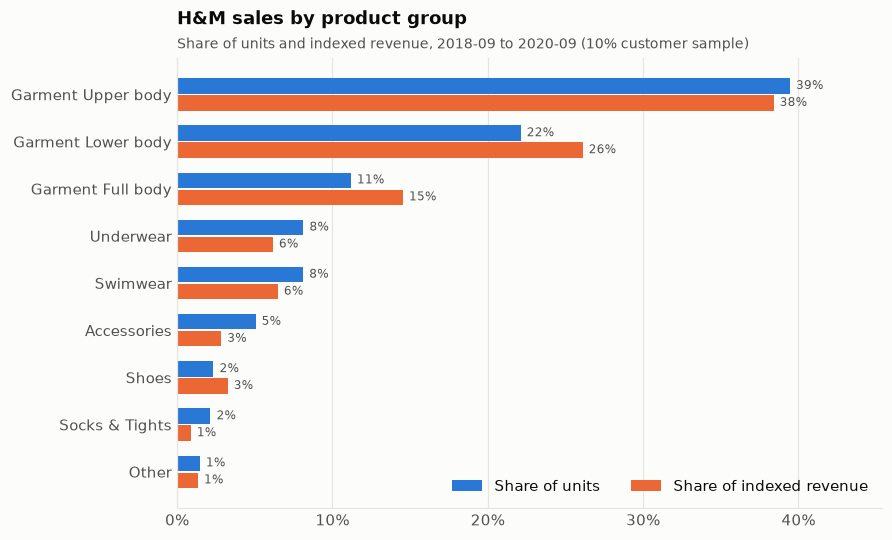

In [4]:
hm_mix = eda.hm_category_mix(con, tx, "product_group_name", TOP_N)
eda.save_table(hm_mix, f"hm_category_mix_{MODE}", TABLES)
display(hm_mix)

fig, ax = viz.new_fig(8, 4.8)
viz.hbar(
    ax,
    list(hm_mix["category"]),
    {"Share of units": hm_mix["unit_share"], "Share of indexed revenue": hm_mix["revenue_share"]},
)
viz.pct_axis(ax, "x")
ax.set_title("H&M sales by product group", pad=22)
period = f"{hm_summary['date_min'][:7]} to {hm_summary['date_max'][:7]}"
viz.subtitle(ax, f"Share of units and indexed revenue, {period} ({SAMPLE_NOTE})")
viz.save_fig(fig, f"eda_hm_category_mix_{MODE}", FIGURES)
plt.show()

Top 15 product types by units, for a finer view of what sells.

In [5]:
hm_types = eda.hm_category_mix(con, tx, "product_type_name", 15)
eda.save_table(hm_types, f"hm_product_type_mix_{MODE}", TABLES)
display(hm_types)

,category,units,indexed_revenue,unit_share,revenue_share
0,Trousers,417348,"14,949,031.4576",0.1322,0.1698
1,Dress,321963,"11,773,917.7966",0.1020,0.1337
2,Sweater,276347,"8,073,771.0000",0.0875,0.0917
3,T-shirt,218006,"2,992,644.4237",0.0690,0.0340
4,Top,156904,"3,192,659.1017",0.0497,0.0363
5,Blouse,148785,"4,198,070.8983",0.0471,0.0477
6,Vest top,140199,"2,194,364.0678",0.0444,0.0249
7,Bra,133448,"3,186,264.8305",0.0423,0.0362
8,Shorts,114408,"2,675,278.4915",0.0362,0.0304
9,Bikini top,111615,"2,558,035.8644",0.0353,0.0291


**Myntra:** the dataset has no category column, so categories here come from simple keyword rules on the product name (`eda.myntra_category_rules` in `config/settings.yaml`). They are rough; Phase 6 replaces them with LLM tags.

,category,listings,median_price,median_discount,share_with_ratings,listing_share
0,Tops & T-shirts,17243,649.0000,0.4505,0.3771,0.1625
1,Ethnic wear,11211,"1,400.0000",0.6002,0.1115,0.1057
2,Innerwear & nightwear,11161,699.0000,0.4400,0.2809,0.1052
3,Jewellery & watches,10481,828.0000,0.6500,0.1985,0.0988
4,Beauty & personal care,9311,450.0000,0.1500,0.2690,0.0878
5,Bags & accessories,8411,749.0000,0.5503,0.1846,0.0793
6,Bottoms,8368,989.0000,0.4505,0.3270,0.0789
7,Home,5806,"1,164.0000",0.5002,0.1450,0.0547
8,Footwear,3951,"1,194.0000",0.4501,0.2759,0.0372
9,Dresses & jumpsuits,2504,"1,154.5000",0.5302,0.2808,0.0236


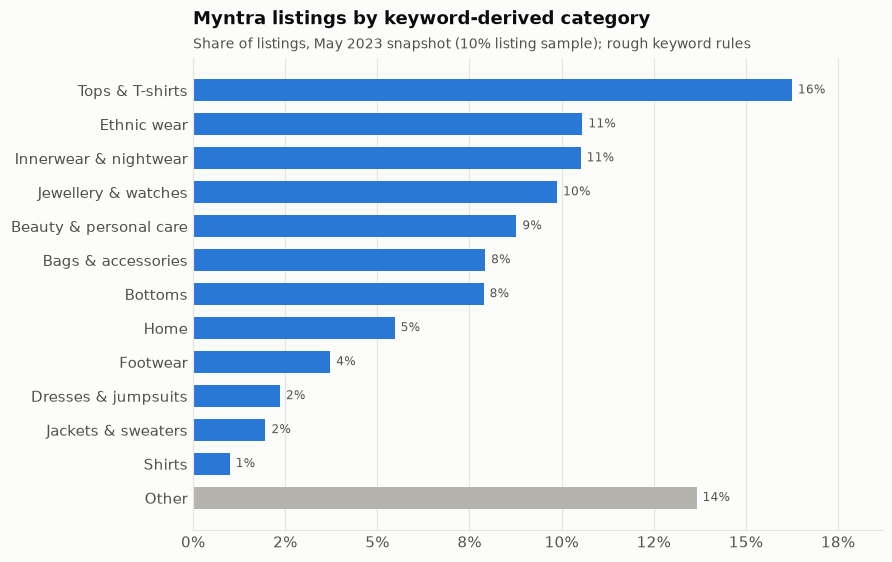

In [6]:
my_mix = eda.myntra_category_mix(con, products, RULES)
eda.save_table(my_mix, f"myntra_category_mix_{MODE}", TABLES)
display(my_mix)

fig, ax = viz.new_fig(8, 5)
viz.hbar(ax, list(my_mix["category"]), {"Share of listings": my_mix["listing_share"]})
viz.pct_axis(ax, "x")
ax.set_title("Myntra listings by keyword-derived category", pad=22)
viz.subtitle(
    ax,
    f"Share of listings, May 2023 snapshot ({SAMPLE_NOTE.replace('customer', 'listing')}); rough keyword rules",
)
viz.save_fig(fig, f"eda_myntra_category_mix_{MODE}", FIGURES)
plt.show()

## 3. H&M sales over time

Weekly units sold. Myntra is a single snapshot, so it has no time dimension.

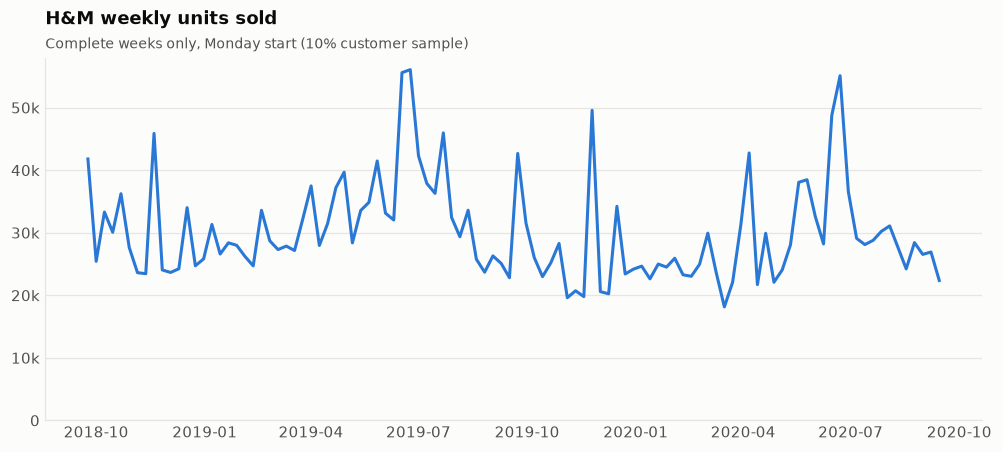

,sales_channel_id,units,indexed_revenue,unit_share,revenue_share
0,1,931899,"21,362,451.0678",0.2951,0.2427
1,2,2225878,"66,672,529.0000",0.7049,0.7573


In [7]:
weekly = eda.hm_weekly_sales(con, tx)
eda.save_table(weekly, f"hm_weekly_sales_{MODE}", TABLES)
# First and last weeks are partial (data starts and ends mid-week).
full_weeks = weekly.iloc[1:-1]

fig, ax = viz.new_fig(9, 4)
ax.plot(full_weeks["week"], full_weeks["units"], color=viz.SERIES[0])
viz.thousands_axis(ax, "y")
ax.set_ylim(bottom=0)
ax.grid(axis="x", visible=False)
ax.set_title("H&M weekly units sold", pad=22)
viz.subtitle(ax, f"Complete weeks only, Monday start ({SAMPLE_NOTE})")
viz.save_fig(fig, f"eda_hm_weekly_units_{MODE}", FIGURES)
plt.show()

channels = eda.hm_channel_mix(con, tx)
eda.save_table(channels, f"hm_channel_mix_{MODE}", TABLES)
display(channels)

## 4. Price distributions

**H&M:** indexed price per unit by product group, from a repeatable random sample (log scale: prices span more than an order of magnitude).

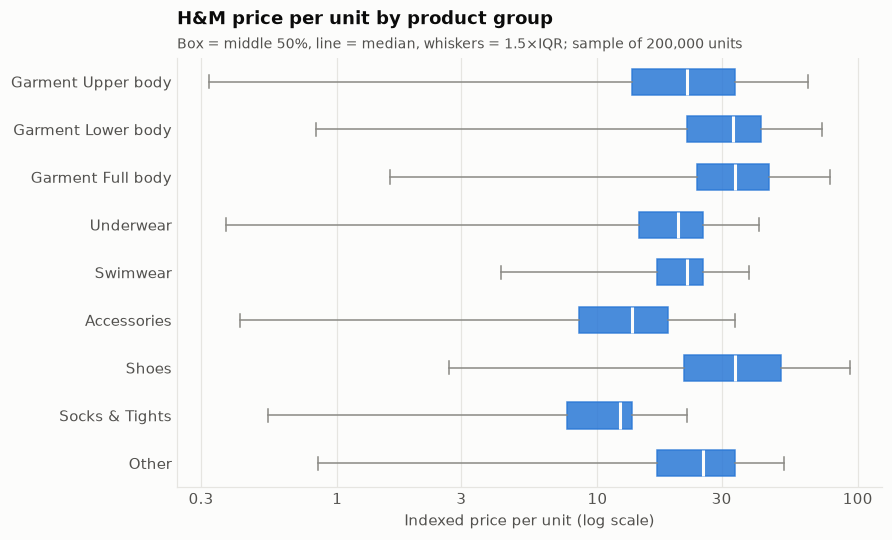

,grp,n,p10,p25,median,p75,p90
0,Garment Upper body,1245755,8.4576,13.5593,22.0169,33.8814,50.8305
1,Garment Lower body,698350,15.2373,22.0169,33.2373,42.3559,50.8305
2,Garment Full body,353218,15.3898,23.7119,33.8814,45.7458,59.3051
3,Underwear,256685,10.1525,14.4068,20.3559,25.4068,33.8814
4,Swimwear,256231,10.8305,16.9322,22.0169,25.4068,33.0000
5,Accessories,159502,5.0678,8.4576,13.5424,18.6271,28.7966
6,Shoes,73938,13.5424,22.0169,33.8814,50.8305,67.7797
7,Socks & Tights,67806,3.3898,7.3898,12.1864,13.5424,16.9322
8,Nightwear,35105,13.5424,16.9322,25.4068,33.8814,40.6610
9,Unknown,9592,16.9322,21.6059,25.4068,31.9492,34.2644


In [8]:
top_groups = [c for c in hm_mix["category"] if c != eda.OTHER]
sample = eda.hm_price_sample(con, tx, N_SAMPLE, SEED, top_groups)
order = top_groups + [eda.OTHER]

fig, ax = viz.new_fig(8, 4.8)
ax.boxplot(
    [sample.loc[sample.category == g, "indexed_price"] for g in order],
    orientation="horizontal",
    tick_labels=order,
    showfliers=False,
    widths=0.55,
    patch_artist=True,
    boxprops=dict(facecolor=viz.SERIES[0], edgecolor=viz.SERIES[0], alpha=0.85),
    medianprops=dict(color=viz.SURFACE, linewidth=2),
    whiskerprops=dict(color=viz.TEXT_MUTED),
    capprops=dict(color=viz.TEXT_MUTED),
)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xticks([0.3, 1, 3, 10, 30, 100], ["0.3", "1", "3", "10", "30", "100"])
ax.minorticks_off()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Indexed price per unit (log scale)")
ax.set_title("H&M price per unit by product group", pad=22)
viz.subtitle(
    ax, f"Box = middle 50%, line = median, whiskers = 1.5×IQR; sample of {len(sample):,} units"
)
viz.save_fig(fig, f"eda_hm_price_by_group_{MODE}", FIGURES)
plt.show()

hm_prices = eda.price_quantiles(con, tx, "indexed_price", "product_group_name")
eda.save_table(hm_prices, f"hm_price_quantiles_{MODE}", TABLES)
display(hm_prices)

**Myntra:** selling price vs MRP (list price) across listings, in rupees, log scale.

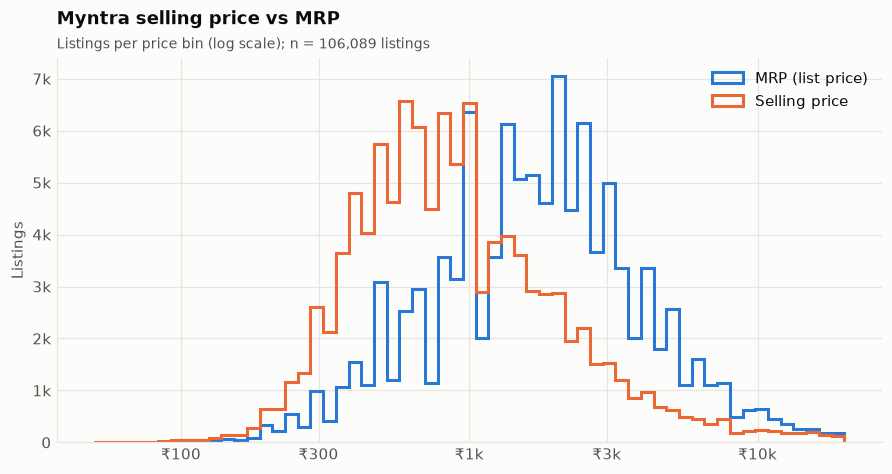

,grp,n,p10,p25,median,p75,p90,measure
0,all,106089,350.0000,499.0000,809.0000,"1,497.0000","2,789.0000",price
0,all,106089,549.0000,999.0000,"1,780.0000","2,999.0000","4,999.0000",mrp


In [9]:
my_sample = eda.myntra_sample(con, products, N_SAMPLE, SEED)
bins = np.logspace(np.log10(50), np.log10(20000), 60)

fig, ax = viz.new_fig(8, 4.2)
ax.hist(
    my_sample["mrp"],
    bins=bins,
    histtype="step",
    linewidth=2,
    color=viz.SERIES[0],
    label="MRP (list price)",
)
ax.hist(
    my_sample["price"],
    bins=bins,
    histtype="step",
    linewidth=2,
    color=viz.SERIES[1],
    label="Selling price",
)
ax.set_xscale("log")
ax.set_xticks([100, 300, 1000, 3000, 10000], ["₹100", "₹300", "₹1k", "₹3k", "₹10k"])
ax.minorticks_off()
viz.thousands_axis(ax, "y")
ax.set_ylabel("Listings")
ax.legend(loc="upper right")
ax.set_title("Myntra selling price vs MRP", pad=22)
viz.subtitle(ax, f"Listings per price bin (log scale); n = {len(my_sample):,} listings")
viz.save_fig(fig, f"eda_myntra_price_dist_{MODE}", FIGURES)
plt.show()

my_prices = pd.concat(
    [
        eda.price_quantiles(con, products, "price").assign(measure="price"),
        eda.price_quantiles(con, products, "mrp").assign(measure="mrp"),
    ]
)
eda.save_table(my_prices, f"myntra_price_quantiles_{MODE}", TABLES)
display(my_prices)

## 5. Discount distributions

Bands come from `pricing.discount_bands` in `config/settings.yaml`.

* **Myntra** discount = 1 − price ÷ MRP, per listing.
* **H&M** has no list price, so this is a **preliminary** proxy: 1 − price ÷ the article's highest observed price (flagged outliers excluded). Phase 3 replaces it with the rolling 8-week P95 reference price from the plan, so treat H&M bands here as a first look, not the final measure.

The two bars measure different things (H&M = share of **units sold**, Myntra = share of **listings**), so compare shapes, not heights.

,band,units,indexed_revenue,median_discount,units_share,indexed_revenue_share
0,0-5%,1800368,"57,361,581.8304",0.0000,0.5701,0.6516
1,5-15%,296670,"8,519,568.5763",0.1001,0.0939,0.0968
2,15-25%,288634,"7,790,171.6610",0.2001,0.0914,0.0885
3,25-35%,148660,"3,418,974.7966",0.3001,0.0471,0.0388
4,35-45%,183430,"4,081,877.2373",0.4002,0.0581,0.0464
5,45-55%,195637,"3,585,728.1525",0.5003,0.0620,0.0407
6,55%+,244378,"3,277,077.8136",0.6123,0.0774,0.0372


,band,listings,share_with_ratings,listings_share
0,0-5%,20087,0.1994,0.1893
1,5-15%,5848,0.2245,0.0551
2,15-25%,6609,0.2586,0.0623
3,25-35%,8150,0.2488,0.0768
4,35-45%,9994,0.2677,0.0942
5,45-55%,14863,0.2964,0.1401
6,55%+,40538,0.2658,0.3821


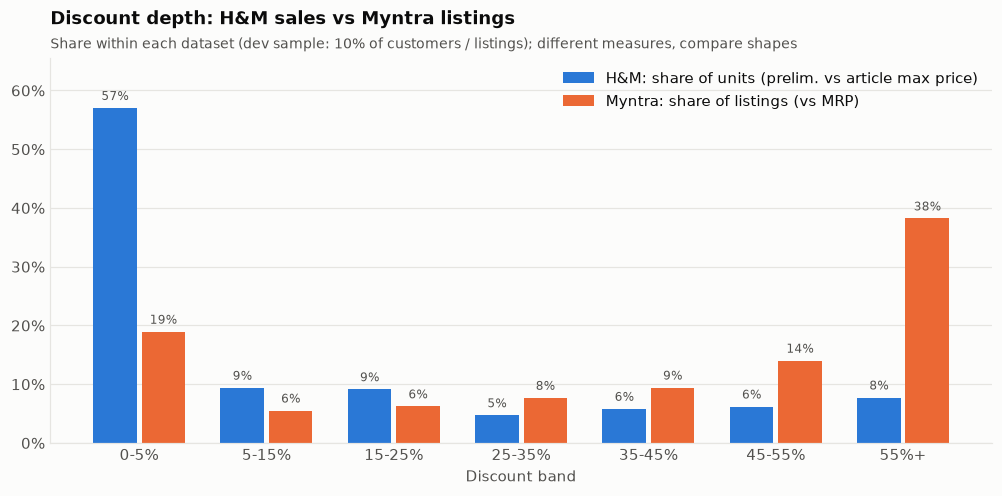

In [10]:
hm_bands = eda.hm_discount_band_mix(con, tx, BANDS["edges"], BANDS["labels"], MAX_DISC)
my_bands = eda.myntra_discount_band_mix(con, products, BANDS["edges"], BANDS["labels"])
eda.save_table(hm_bands, f"hm_discount_bands_prelim_{MODE}", TABLES)
eda.save_table(my_bands, f"myntra_discount_bands_{MODE}", TABLES)
display(hm_bands)
display(my_bands)

fig, ax = viz.new_fig(9, 4.4)
viz.vbar(
    ax,
    BANDS["labels"],
    {
        "H&M: share of units (prelim. vs article max price)": hm_bands["units_share"],
        "Myntra: share of listings (vs MRP)": my_bands["listings_share"],
    },
)
viz.pct_axis(ax, "y")
ax.set_xlabel("Discount band")
ax.set_title("Discount depth: H&M sales vs Myntra listings", pad=22)
scope = "dev sample: 10% of customers / listings" if MODE == "dev" else "full data"
viz.subtitle(ax, f"Share within each dataset ({scope}); different measures, compare shapes")
viz.save_fig(fig, f"eda_discount_bands_{MODE}", FIGURES)
plt.show()

## 6. Takeaways

Key figures below are computed from the tables above (not typed in), so they update when the notebook is re-run on full data.

In [11]:
garments = hm_mix[hm_mix["category"].str.startswith("Garment")]
online = channels.loc[channels["unit_share"].idxmax()]
peak = full_weeks.loc[full_weeks["units"].idxmax(), "week"]
hm_full_price = hm_bands.loc[hm_bands["band"] == BANDS["labels"][0], "units_share"].item()
my_top_band = my_bands.loc[my_bands["listings_share"].idxmax()]
my_other = my_mix.loc[my_mix["category"] == eda.OTHER, "listing_share"].sum()

takeaways = pd.Series(
    {
        "Rows removed by cleaning (H&M / Myntra)": f"{hm_summary['raw_rows'] - hm_summary['final_rows'] - hm_summary['dropped_dev_sample']:,} / "
        f"{my_summary['raw_rows'] - my_summary['final_rows'] - my_summary.get('dropped_dev_sample', 0):,}",
        "H&M garments (upper/lower/full body) share of units": f"{garments['unit_share'].sum():.0%}",
        "H&M garments share of indexed revenue": f"{garments['revenue_share'].sum():.0%}",
        f"H&M channel {int(online.sales_channel_id)} share of units": f"{online.unit_share:.0%}",
        "H&M busiest complete week (starting)": str(peak.date()),
        "H&M units sold within 5% of article max price (prelim.)": f"{hm_full_price:.0%}",
        "Myntra largest discount band": f"{my_top_band.band} ({my_top_band.listings_share:.0%} of listings)",
        "Myntra listings with at least one rating": f"{con.execute(f'SELECT avg((rating_total > 0)::INT) FROM {products}').fetchone()[0]:.0%}",
        "Myntra listings not matched by keyword rules": f"{my_other:.0%}",
    },
    name="value",
)
eda.save_table(takeaways.rename_axis("fact").reset_index(), f"eda_key_facts_{MODE}", TABLES)
display(takeaways.to_frame())

,value
Rows removed by cleaning (H&M / Myntra),0 / 0
H&M garments (upper/lower/full body) share of units,73%
H&M garments share of indexed revenue,79%
H&M channel 2 share of units,70%
H&M busiest complete week (starting),2019-06-24
H&M units sold within 5% of article max price (prelim.),57%
Myntra largest discount band,55%+ (38% of listings)
Myntra listings with at least one rating,25%
Myntra listings not matched by keyword rules,14%


**What this means for the next phases**

* **Data quality is high.** No rows fail the cleaning rules; the main quirks are duplicate rows (kept, because each H&M row is one unit) and a handful of flagged prices.
* **Garments dominate H&M sales**, and lower- and full-body garments earn a larger share of revenue than of units (higher prices), while accessories, underwear and socks are the reverse. Category-level analysis in Phase 3 should focus on the large garment groups, where there is enough volume.
* **Strong seasonality.** Weekly units peak around late June in both years (summer sale season) and spike in late November (Black Friday). The forecast in Phase 5 needs yearly seasonality, and the discount analysis needs week fixed effects so seasonal peaks are not mistaken for discount effects.
* **H&M markdowns come in round steps.** The median discount inside each band sits at about 10%, 20%, 30%, 40% and 50%, which suggests deliberate markdown levels and makes a band-based payback analysis natural. The H&M bands here use a preliminary reference price (article max) and will be re-measured in Phase 3.
* **Myntra skews to deep discounts.** The largest share of listings sits in the deepest band, consistent with MRP acting as an anchor price. Most listings have no ratings, so rating count is a thin demand proxy; the Phase 3 cross-check must stay directional.
* **Myntra categories are rough.** Keyword rules leave a noticeable share unmatched; Phase 6 (LLM tagging) is the proper fix.